# Do mice use the odor to find the target?

**Task.** Each trial hides one target cell in a 3 x 9 grid. On `flip_state` 0 the target is in the four rows at the low-y end of the arena and odor is delivered at that end; on `flip_state` 1 both are at the high-y end; on `flip_state` 2 there is no odor and the target can be anywhere. Odor stays on until the mouse's nose enters the target cell. The mouse then drinks at a port in the middle row, waits out a 1-3 s ITI, and the next trial starts.

**What a mouse that had learned the task would do.** Go to the odor end, and stay there until it finds the target. That gives two separable behaviors to look for:

1. **Direction** - which end does the mouse head for? (flip 0 vs flip 1)
2. **Persistence** - once at the correct end, does it stay? (odor vs no-odor)

**Why the comparisons are built the way they are.** A search ends the moment the target is found, so on a flip-0 trial every path ends at the low end no matter what the mouse was doing. Occupancy, mean position and time-at-odor-end therefore differ between flip 0 and flip 1 even for a mouse wandering at random, and are not used here. Instead:

- *Direction* uses only trials that begin in the neutral middle row and asks which end zone is entered first. A trial cannot end before the mouse has entered the target's zone, so this is not affected by where the target is.
- *Persistence and search cost* compare each odor trial against **no-odor trials with the target in the same cell and the mouse starting in the same zone**. Those trials pose an identical search problem; the only thing that differs is the odor.

Zones: `low` = y < 890 px (flip-0 target rows), `high` = y >= 1068 px (flip-1 target rows), `mid` = the row between them, which holds both water ports. Only `x` sessions (1% pinene) are analysed, and each mouse contributes ten of them: x1 to x10 (x1-x6 and x8-x11 for mouse 9007, which has no x7). The `o` and `t` sessions were shaping sessions and are left out, as is x0, which only three mice ran.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as sps

from src import config as cfg
from src.trials import load_trials          # run `python -m src.trials` to rebuild output/trials.csv
from src.stats import stratified_diff, per_mouse, summarize, logistic_fit

pd.set_option('display.width', 200, 'display.precision', 3)

SESSION_TYPES = ['x']
FLIP_COLOR = {0: '#2a78d6', 1: '#eb6834', 2: '#8a8985'}
FLIP_LABEL = {0: 'flip 0 (odor low)', 1: 'flip 1 (odor high)', 2: 'flip 2 (no odor)'}
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
    'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'text.color': INK,
    'axes.titlesize': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'xtick.labelsize': 8, 'ytick.labelsize': 8, 'legend.fontsize': 8,
    'legend.frameon': False, 'figure.dpi': 110,
})

t = load_trials()

## 1. Data

One row per searched trial. A search runs from the first frame of a trial (ITI over, odor on) to the frame `target_cell` goes NaN (target consumed, odor off). Trial 0 (free reward) and trials whose target was never found are dropped. On every remaining trial the tracked nose is inside the target cell on the final frame, which confirms the grid geometry.

In [2]:
print(f"{len(t)} searched trials, {t.groupby(['mouse', 'session']).ngroups} sessions, {t.mouse.nunique()} mice")
print(f"nose inside target cell at encounter: {(t.found_err_px == 0).mean():.1%}")
overview = t.groupby('session_type').agg(
    mice=('mouse', 'nunique'), sessions=('session', lambda s: t.loc[s.index].groupby(['mouse', 'session']).ngroups),
    trials=('trial', 'size'), median_search_s=('search_s', 'median'), median_path_px=('path_px', 'median'))
overview.join(pd.crosstab(t.session_type, t.flip).add_prefix('n_flip')).loc[SESSION_TYPES]

10621 searched trials, 90 sessions, 9 mice
nose inside target cell at encounter: 100.0%


,mice,sessions,trials,median_search_s,median_path_px,n_flip0,n_flip1,n_flip2
session_type,,,,,,,,
x,9,90,10621,7.268,3741.701,3529,3549,3543


## 2. Behavioral idiosyncrasies

Three things to pin down before reading anything into flip-state differences.

**Is the mouse's position at odor onset independent of the trial type?** It has to be - the mouse has no information yet. This is the negative control for everything below.

**Side bias.** Does the mouse favor one end regardless of trial type?

**Return to the previous target.** By the time the ITI ends, has the mouse drifted back toward where it last found a target?

In [3]:
start = pd.crosstab(t.flip, t.start_zone, normalize='index')[['low', 'mid', 'high']]
chi2, p, *_ = sps.chi2_contingency(pd.crosstab(t.flip[t.odor], t.start_zone[t.odor]))
print(f"Zone at odor onset, flip 0 vs flip 1: chi2 = {chi2:.2f}, p = {p:.2f}")
start.rename(index=FLIP_LABEL)

Zone at odor onset, flip 0 vs flip 1: chi2 = 0.89, p = 0.64


start_zone,low,mid,high
flip,,,
flip 0 (odor low),0.469,0.153,0.378
flip 1 (odor high),0.480,0.149,0.371
flip 2 (no odor),0.459,0.144,0.397


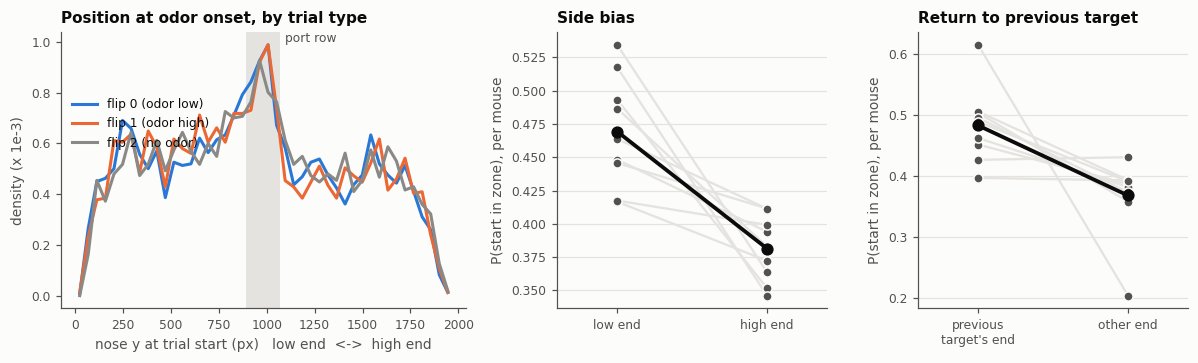

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), gridspec_kw={'width_ratios': [1.5, 1, 1]})

ax = axes[0]
bins = np.linspace(0, cfg.FRAME_H, 45)
for flip in (0, 1, 2):
    density, _ = np.histogram(t.start_y[t.flip == flip], bins=bins, density=True)
    ax.plot((bins[:-1] + bins[1:]) / 2, density * 1000, color=FLIP_COLOR[flip], lw=2, label=FLIP_LABEL[flip])
ax.axvspan(cfg.LOW_MAX_Y, cfg.HIGH_MIN_Y, color=GRID, lw=0)
ax.text(cfg.HIGH_MIN_Y + 25, ax.get_ylim()[1], 'port row', ha='left', va='top', fontsize=8, color=MUTED)
ax.set(xlabel='nose y at trial start (px)   low end  <->  high end', ylabel='density (x 1e-3)',
       title='Position at odor onset, by trial type')
ax.legend(loc='upper left', bbox_to_anchor=(0.0, 0.8))

def paired_dots(ax, a, b, labels, title, ylabel):
    for m in a.index:
        ax.plot([0, 1], [a[m], b[m]], color=GRID, lw=1.5, zorder=1)
    ax.scatter(np.zeros(len(a)), a, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.scatter(np.ones(len(b)), b, s=36, color=MUTED, zorder=2, edgecolor='#fcfcfb', lw=1)
    ax.plot([0, 1], [a.mean(), b.mean()], color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.set(xticks=[0, 1], xticklabels=labels, xlim=(-0.4, 1.4), title=title, ylabel=ylabel)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)

by_mouse = t.groupby('mouse')
paired_dots(axes[1], by_mouse.start_zone.apply(lambda z: (z == 'low').mean()),
            by_mouse.start_zone.apply(lambda z: (z == 'high').mean()),
            ['low end', 'high end'], 'Side bias', 'P(start in zone), per mouse')
prev = t[t.prev_target_zone.isin(['low', 'high'])]
prev_by_mouse = prev.groupby('mouse')[['start_zone', 'prev_target_zone']]
paired_dots(axes[2], prev_by_mouse.apply(lambda d: (d.start_zone == d.prev_target_zone).mean()),
            prev_by_mouse.apply(lambda d: ((d.start_zone != d.prev_target_zone) & (d.start_zone != 'mid')).mean()),
            ["previous\ntarget's end", 'other end'], 'Return to previous target', 'P(start in zone), per mouse')
plt.tight_layout(); plt.show()

The control holds: position at odor onset is the same for flip 0 and flip 1. Mice do have a mild preference for the low end and a mild tendency to be back at the previous target's end when the next trial starts. Both are handled below by never comparing trials across different start zones, and by stratifying the direction analysis on the previous target's end.

## 3. Direction: which end does the mouse go to first?

Trials that start in the neutral middle row only. `P(low end first)` should be near 1 on flip 0 and near 0 on flip 1 for a mouse following the odor; flip 2 shows that mouse's side bias.

**Discrimination** = P(low first | flip 0) - P(low first | flip 1), computed within mouse x previous-target-end strata so that a return-to-previous-target habit cannot produce it. 0 = odor side ignored, 1 = perfect.

In [5]:
mid = t[(t.start_zone == 'mid') & (t.first_entry != 'none')].copy()
mid['low_first'] = (mid.first_entry == 'low').astype(float)
mid['is_flip0'] = mid.flip == 0

rows = {}
for st in SESSION_TYPES:
    d = mid[mid.session_type == st]
    p_low = d.groupby('flip').low_first.mean()
    rows[st] = {'P(low first) flip 0': p_low[0], 'flip 2': p_low[2], 'flip 1': p_low[1],
                **summarize(d[d.odor], 'low_first', 'is_flip0', ['prev_target_zone'])}
direction = pd.DataFrame(rows).T.rename(columns={'effect': 'discrimination'})
direction

,P(low first) flip 0,flip 2,flip 1,discrimination,p_perm,mouse_mean,ci_lo,ci_hi,mice_same_sign,n_trials
x,0.519,0.499,0.522,-0.003,0.925,-0.022,-0.153,0.108,3/9,1069


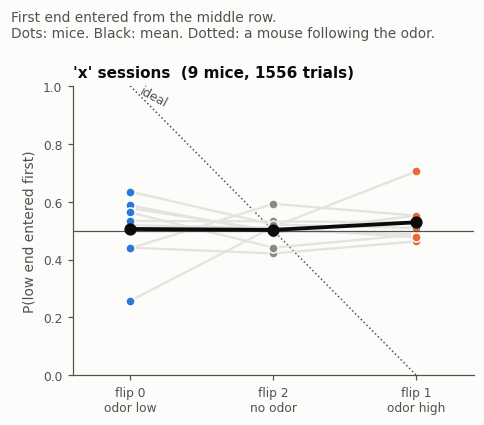

In [6]:
fig, axes = plt.subplots(1, len(SESSION_TYPES), figsize=(3.6 * len(SESSION_TYPES) + 0.8, 3.9), sharey=True, squeeze=False)
axes = axes[0]
order = [0, 2, 1]
for ax, st in zip(axes, SESSION_TYPES):
    d = mid[mid.session_type == st]
    pm = d.groupby(['mouse', 'flip']).low_first.mean().unstack()[order]
    for m in pm.index:
        ax.plot(range(3), pm.loc[m], color=GRID, lw=1.5, zorder=1)
    for i, flip in enumerate(order):
        ax.scatter(np.full(len(pm), i), pm[flip], s=36, color=FLIP_COLOR[flip], edgecolor='#fcfcfb', lw=1, zorder=2)
    ax.plot(range(3), pm.mean(), color=INK, lw=2.5, marker='o', ms=7, zorder=3)
    ax.plot(range(3), [1, 0.5, 0], color=MUTED, lw=1, ls=':', zorder=0)
    ax.axhline(0.5, color=MUTED, lw=0.8)
    ax.set(xticks=range(3), xticklabels=['flip 0\nodor low', 'flip 2\nno odor', 'flip 1\nodor high'], xlim=(-0.4, 2.4),
           ylim=(0, 1), title=f"'{st}' sessions  ({len(pm)} mice, {len(d)} trials)")
axes[0].set_ylabel('P(low end entered first)')
axes[0].text(0.05, 0.93, 'ideal', color=MUTED, fontsize=8, rotation=-28)
fig.suptitle('First end entered from the middle row.\nDots: mice. Black: mean. Dotted: a mouse following the odor.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

The same question as a regression, so the odor's pull can be read next to the two idiosyncrasies on a common scale (log-odds of entering the low end first; mouse identity ignored, coefficients are descriptive):

In [7]:
def choice_model(d):
    X = np.c_[(d.flip == 0).astype(float) - (d.flip == 1), (d.prev_target_zone == 'low').astype(float) - (d.prev_target_zone == 'high')]
    intercept, coef = logistic_fit(X, d.low_first)
    return pd.Series({'odor side': coef[0], "previous target's side": coef[1], 'low-end bias': intercept})

pd.DataFrame({st: choice_model(mid[mid.session_type == st]) for st in SESSION_TYPES}).T

,odor side,previous target's side,low-end bias
x,-0.007,0.055,0.056


## 4. Persistence and search cost: odor vs matched no-odor trials

Each search is split at the first frame the mouse is in the target's end zone:

- **approach** - everything before that (zero if the mouse started there). `wrong_end_first`: it visited the other end before the correct one.
- **local search** - everything after. `left_after_reach`: having been at the correct end, it went all the way to the other end before finding the target.

Effects are odor minus no-odor, within strata of mouse x target cell x start zone. Matching on the exact cell matters: flip 0 and flip 1 draw the center cell of their second row twice as often as any other, and those cells are easier to hit. Path effects are log2 ratios (-0.15 is about 10% shorter). Searches longer than `MAX_SEARCH_S` are dropped as disengaged.

In [8]:
MATCH = ['target_cell', 'start_zone']
METRICS = {   # name: (column, which trials)
    'whole search path (log2)':      ('log2_path_px',       ['same end', 'opposite end', 'from middle']),
    'approach path (log2)':          ('log2_reach_path_px', ['opposite end', 'from middle']),
    'P(wrong end first)':            ('wrong_end_first',    ['from middle']),
    'local search path (log2)':      ('log2_local_path_px', ['same end', 'opposite end', 'from middle']),
    'P(left correct end)':           ('left_after_reach',   ['same end', 'opposite end', 'from middle']),
}
cost = t[(t.geometry != 'target in middle') & (t.search_s <= cfg.MAX_SEARCH_S)]

rows = {}
for st in SESSION_TYPES:
    for name, (col, geoms) in METRICS.items():
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        base = d.loc[~d.odor, col].mean()
        rows[(st, name)] = {'no-odor mean': base, **summarize(d, col, 'odor', MATCH)}
matched = pd.DataFrame(rows).T
matched

no-odor mean effect p_perm mouse_mean  ci_lo  ci_hi mice_same_sign n_trials
x whole search path (log2)       11.714 -0.117  0.007     -0.115  -0.24  0.009            7/9    10043
  approach path (log2)           10.439  -0.11  0.006     -0.109 -0.224  0.006            7/9     5817
  P(wrong end first)              0.525 -0.044  0.149     -0.037 -0.119  0.044            6/9     1491
  local search path (log2)       10.958 -0.085  0.093     -0.079 -0.223  0.064            7/9    10043
  P(left correct end)             0.464 -0.034  0.003     -0.033 -0.057 -0.009            7/9    10043

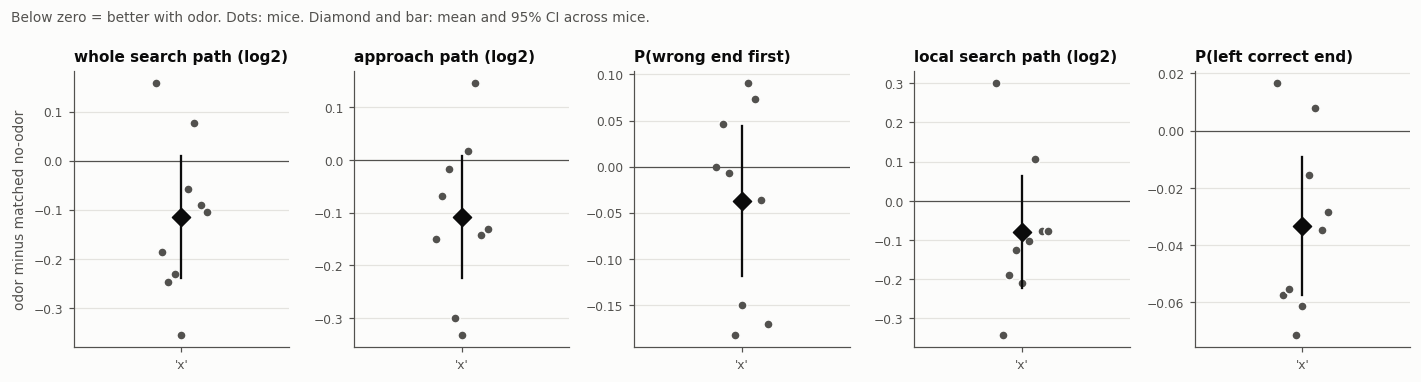

In [9]:
fig, axes = plt.subplots(1, len(METRICS), figsize=(13, 3.5))
for ax, (name, (col, geoms)) in zip(axes, METRICS.items()):
    for i, st in enumerate(SESSION_TYPES):
        d = cost[(cost.session_type == st) & cost.geometry.isin(geoms)]
        pm = per_mouse(d, col, 'odor', MATCH).dropna()
        jitter = np.linspace(-0.12, 0.12, len(pm))
        ax.scatter(i + jitter, pm, s=36, color=MUTED, edgecolor='#fcfcfb', lw=1, zorder=2)
        r = matched.loc[(st, name)]
        ax.plot([i, i], [r.ci_lo, r.ci_hi], color=INK, lw=1.5, zorder=3)
        ax.scatter([i], [r.mouse_mean], s=70, color=INK, marker='D', zorder=4)
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(xticks=range(len(SESSION_TYPES)), xticklabels=[f"'{s}'" for s in SESSION_TYPES],
           xlim=(-0.5, len(SESSION_TYPES) - 0.5), title=name)
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].set_ylabel('odor minus matched no-odor')
fig.suptitle('Below zero = better with odor. Dots: mice. Diamond and bar: mean and 95% CI across mice.',
             x=0.01, ha='left', fontsize=9, color=MUTED)
plt.tight_layout(); plt.show()

### Do the two odor conditions differ from each other?

The same matched comparison, separately for flip 0 (against no-odor trials with a low-end target) and flip 1 (against no-odor trials with a high-end target).

In [10]:
rows = {}
for st in SESSION_TYPES:
    for flip, zone in ((0, 'low'), (1, 'high')):
        d = cost[(cost.session_type == st) & (cost.target_zone == zone)]
        rows[(st, FLIP_LABEL[flip])] = {
            'P(left correct end), odor': d.loc[d.odor, 'left_after_reach'].mean(),
            'no odor': d.loc[~d.odor, 'left_after_reach'].mean(),
            'matched diff': stratified_diff(d, 'left_after_reach', 'odor', ['mouse'] + MATCH),
            'whole path (log2), matched diff': stratified_diff(d, 'log2_path_px', 'odor', ['mouse'] + MATCH),
            'n odor': int(d.odor.sum()), 'n no odor': int((~d.odor).sum())}
pd.DataFrame(rows).T

P(left correct end), odor  no odor  matched diff  whole path (log2), matched diff  n odor  n no odor
x flip 0 (odor low)                       0.443    0.466        -0.019                           -0.100  3510.0     1511.0
  flip 1 (odor high)                      0.398    0.461        -0.049                           -0.135  3526.0     1496.0

## 5. Across sessions

Both measures by how many sessions the mouse has had (its 1st to 10th), pooling mice. If mice were learning, discrimination should climb toward 1 and the persistence effect should grow more negative.

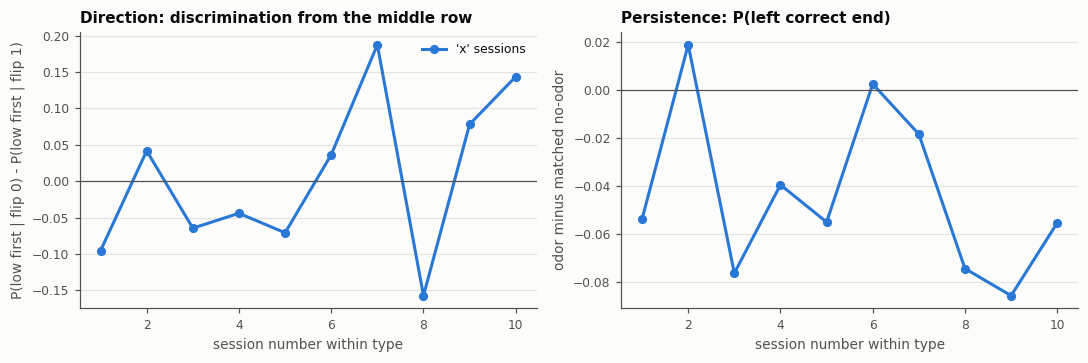

In [11]:
def by_session(d, y, label, keys, min_trials):
    out = d.groupby(['session_type', 'session_num'])[[y, label] + keys].apply(
        lambda g: pd.Series({'effect': stratified_diff(g, y, label, keys), 'n': len(g)}))
    return out[out.n >= min_trials]

disc = by_session(mid[mid.odor], 'low_first', 'is_flip0', ['mouse'], 30)
pers = by_session(cost, 'left_after_reach', 'odor', ['mouse', 'target_zone', 'start_zone'], 150)

TYPE_COLOR = {'x': '#2a78d6'}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, data, title, ylabel in ((axes[0], disc, 'Direction: discrimination from the middle row', 'P(low first | flip 0) - P(low first | flip 1)'),
                                (axes[1], pers, 'Persistence: P(left correct end)', 'odor minus matched no-odor')):
    for st in SESSION_TYPES:
        s = data.loc[st].effect
        ax.plot(s.index, s.values, color=TYPE_COLOR[st], lw=2, marker='o', ms=5, label=f"'{st}' sessions")
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.set(title=title, ylabel=ylabel, xlabel='session number within type')
    ax.yaxis.grid(True, color=GRID); ax.set_axisbelow(True)
axes[0].legend()
plt.tight_layout(); plt.show()

## Summary

**Mice are not solving the task as designed.** A mouse using the odor would enter the odor end first and stay there. Mice starting from the middle row enter the wrong end first about half the time, and having reached the correct end they abandon it for the far end on over 40% of trials before finding the target.

**Direction (flip 0 vs flip 1).** From the middle row (9 mice, 1,069 odor trials), discrimination is 0.00 (95% CI across mice -0.15 to 0.11). The odor side has no detectable influence on which end the mouse goes to. In the regression its weight (-0.01) is smaller than either the previous-target habit (0.06) or the low-end bias (0.06).

**Odor vs matched no-odor (persistence and cost).** Odor trials are slightly cheaper than no-odor trials with the same target cell and start zone. The search path is about 8% shorter (log2 ratio -0.12, p = 0.007, 7/9 mice) and mice leave the correct end on 3.4 percentage points fewer trials than the 46% no-odor baseline (p = 0.003, 7/9 mice). The effect is present for both odor ends. It is real but small: perfect use of the odor would take that 46% to near zero.

**Idiosyncrasies.** Position at odor onset is independent of trial type (p = 0.64), so the ITI gives nothing away. Mice start in the low end more often than the high end (47% vs 38%) and are more likely to be at the previous target's end than the other one (48% vs 37%). Neither can produce the effects above, because comparisons are made within start zone and within previous-target end.

**No learning across sessions.** Neither measure trends over the ten sessions.

**Reading the results.**
- The odor-vs-no-odor difference shows that *something* about odor trials reaches the mice, but it does not have to be the pinene: anything that coincides with odor delivery (valve sound, airflow) would produce the same result. This analysis cannot separate those.
- The pattern - no directional choice from a distance, slightly more staying once at the odor end - is what a cue detectable only near its source would produce.
- p-values are unadjusted across the 5 tests in section 4; the three at p <= 0.007 (whole path, approach path, leaving the correct end) survive a Bonferroni correction, the others do not.
- Excluded: the `o` and `t` shaping sessions, sessions beyond each mouse's ten, trial 0 of each session, trials with no target found, and (section 4 only) searches over 120 s (0.7% of trials) and no-odor trials with the target in the middle row.